In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url1 = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
local_copy = "Titanic-Dataset.csv"
df = pd.read_csv(url1)

# Выведем общую информацию о датасете
print("Информация о датасете:")
display(df.info())

print("\nПервые 5 строк:")
display(df.head())

print("\nПропущенные значения:")
display(df.isnull().sum())

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


None


Первые 5 строк:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Пропущенные значения:


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

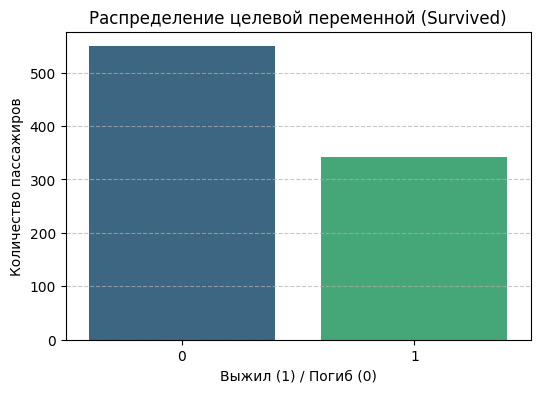

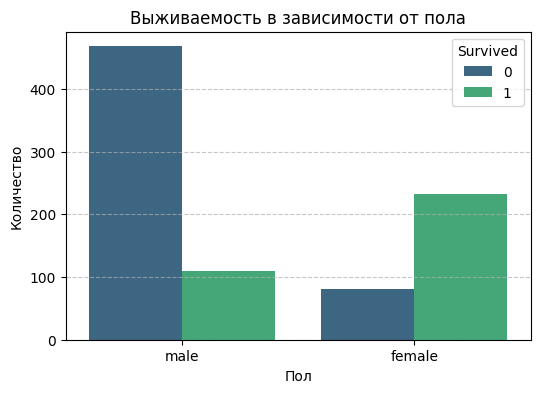

In [2]:
# Визуализация распределения целевой переменной
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Survived', palette='viridis', hue='Survived', legend=False)
plt.title('Распределение целевой переменной (Survived)')
plt.xlabel('Выжил (1) / Погиб (0)')
plt.ylabel('Количество пассажиров')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Распределение выживаемости по полу
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Sex', hue='Survived', palette='viridis')
plt.title('Выживаемость в зависимости от пола')
plt.xlabel('Пол')
plt.ylabel('Количество')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

=== Dummy Baseline ===
Test Accuracy:  0.6145
Test Precision: 0.0000
Test Recall:    0.0000
Test F1-score:  0.0000



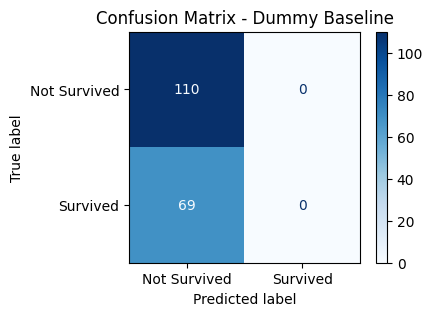

--------------------------------------------------


In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Подготовка базовых данных (без продвинутого Feature Engineering), чтобы инициализировать X_train и X_test
data_base = df.copy()
# дроп passengerID, name и других не играющих роли паарметров
data_base = data_base.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

X_base = data_base.drop(columns=['Survived'])
y_base = data_base['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X_base, y_base, test_size=0.2, random_state=42, stratify=y_base
)

# Простая импутация базовых данных
age_median_val = X_train['Age'].median()
embarked_mode_val = X_train['Embarked'].mode()[0]

X_train['Age'] = X_train['Age'].fillna(age_median_val)
X_test['Age'] = X_test['Age'].fillna(age_median_val)

X_train['Embarked'] = X_train['Embarked'].fillna(embarked_mode_val)
X_test['Embarked'] = X_test['Embarked'].fillna(embarked_mode_val)

X_train = pd.get_dummies(X_train, columns=['Sex', 'Embarked'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['Sex', 'Embarked'], drop_first=True)
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

# Явно инициализируем словарь результатов
results = {}

# Функция для оценки моделей и построения confusion matrix
def evaluate_model(model_name, y_true, y_pred, y_train_true=None, y_train_pred=None):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    results[model_name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-score': f1
    }

    print(f"=== {model_name} ===")
    if y_train_true is not None and y_train_pred is not None:
        train_f1 = f1_score(y_train_true, y_train_pred, zero_division=0)
        print(f"Train F1-score: {train_f1:.4f}")
    print(f"Test Accuracy:  {acc:.4f}")
    print(f"Test Precision: {prec:.4f}")
    print(f"Test Recall:    {rec:.4f}")
    print(f"Test F1-score:  {f1:.4f}\n")

    # Визуализация матрицы ошибок
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Survived', 'Survived'])
    fig, ax = plt.subplots(figsize=(4, 3))
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.show()
    print("-"*50)

# 1. Dummy Baseline
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
evaluate_model('Dummy Baseline', y_test, dummy.predict(X_test))

In [4]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_validate, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, make_scorer
from sklearn.preprocessing import StandardScaler

# Гарантируем подготовку признаков с продвинутым Feature Engineering
data_tuned = df.copy()
data_tuned['Title'] = data_tuned['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
data_tuned['Title'] = data_tuned['Title'].replace(['Lady', 'Countess','Capt', 'Col','Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
data_tuned['Title'] = data_tuned['Title'].replace('Mlle', 'Miss')
data_tuned['Title'] = data_tuned['Title'].replace('Ms', 'Miss')
data_tuned['Title'] = data_tuned['Title'].replace('Mme', 'Mrs')

data_tuned['FamilySize'] = data_tuned['SibSp'] + data_tuned['Parch'] + 1
data_tuned['IsAlone'] = (data_tuned['FamilySize'] == 1).astype(int)
data_tuned = data_tuned.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

X_t = data_tuned.drop(columns=['Survived'])
y_t = data_tuned['Survived']

from sklearn.model_selection import train_test_split
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_t, y_t, test_size=0.2, random_state=42, stratify=y_t
)

age_med = X_train_t['Age'].median()
emb_mode = X_train_t['Embarked'].mode()[0]
X_train_t['Age'] = X_train_t['Age'].fillna(age_med)
X_test_t['Age'] = X_test_t['Age'].fillna(age_med)
X_train_t['Embarked'] = X_train_t['Embarked'].fillna(emb_mode)
X_test_t['Embarked'] = X_test_t['Embarked'].fillna(emb_mode)

X_train_t = pd.get_dummies(X_train_t, columns=['Sex', 'Embarked', 'Title'], drop_first=True)
X_test_t = pd.get_dummies(X_test_t, columns=['Sex', 'Embarked', 'Title'], drop_first=True)
X_train_t, X_test_t = X_train_t.align(X_test_t, join='left', axis=1, fill_value=0)

# Исходный baseline
baseline_rf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
baseline_rf.fit(X_train_t, y_train_t)

baseline_train_pred = baseline_rf.predict(X_train_t)
baseline_test_pred = baseline_rf.predict(X_test_t)

# Фиксируем качество baseline
print('=== Baseline Model (До оптимизации) ===')
print(f'Train F1: {f1_score(y_train_t, baseline_train_pred):.4f}')
print(f'Test F1:  {f1_score(y_test_t, baseline_test_pred):.4f}\n')

# Сетка параметров
param_grid = {
    'n_estimators': [10, 50, 100, 150, 200],
    'max_depth': [2, 4, 6, 8, 12],
    'min_samples_split': [2, 5, 10, 20]
}

# 5-fold Stratified CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f1_scorer = make_scorer(f1_score)

# --- Grid Search ---
print('Запуск Grid Search...')
start_grid = time.time()
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring=f1_scorer,
    cv=cv,
    n_jobs=-1
)
grid_search.fit(X_train_t, y_train_t)
end_grid = time.time()

grid_time = end_grid - start_grid
print(f'Grid Search завершен за {grid_time:.2f} сек.')
print(f'Лучшие параметры Grid: {grid_search.best_params_}')
print(f'Лучший CV F1: {grid_search.best_score_:.4f}\n')

# --- Random Search ---
print('Запуск Random Search...')
n_iter_search = 20
start_random = time.time()
random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_grid,
    n_iter=n_iter_search,
    scoring=f1_scorer,
    cv=cv,
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_t, y_train_t)
end_random = time.time()

random_time = end_random - start_random
print(f'Random Search завершен за {random_time:.2f} сек.')
print(f'Лучшие параметры Random: {random_search.best_params_}')
print(f'Лучший CV F1: {random_search.best_score_:.4f}\n')

=== Baseline Model (До оптимизации) ===
Train F1: 0.8039
Test F1:  0.7752

Запуск Grid Search...
Grid Search завершен за 18.31 сек.
Лучшие параметры Grid: {'max_depth': 4, 'min_samples_split': 2, 'n_estimators': 150}
Лучший CV F1: 0.7657

Запуск Random Search...
Random Search завершен за 2.32 сек.
Лучшие параметры Random: {'n_estimators': 200, 'min_samples_split': 20, 'max_depth': 4}
Лучший CV F1: 0.7657



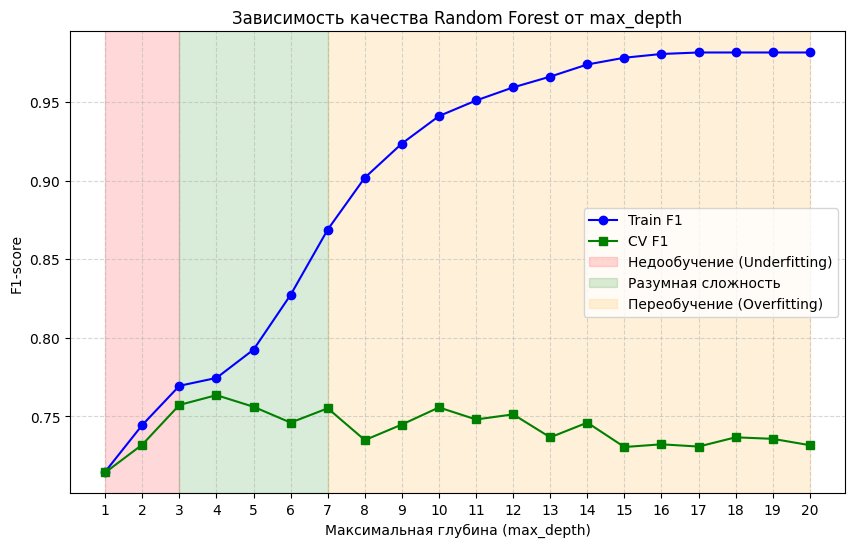

In [5]:
# Исследование влияния гиперпараметров и поиск областей недо-/переобучения
depths = list(range(1, 21))
train_scores = []
cv_scores = []

for d in depths:
    model = RandomForestClassifier(n_estimators=100, max_depth=d, random_state=42)
    scores = cross_validate(model, X_train_t, y_train_t, cv=cv, scoring='f1', return_train_score=True)
    train_scores.append(np.mean(scores['train_score']))
    cv_scores.append(np.mean(scores['test_score']))

plt.figure(figsize=(10, 6))
plt.plot(depths, train_scores, 'o-', label='Train F1', color='blue')
plt.plot(depths, cv_scores, 's-', label='CV F1', color='green')

# Разметка областей
plt.axvspan(1, 3, alpha=0.15, color='red', label='Недообучение (Underfitting)')
plt.axvspan(3, 7, alpha=0.15, color='green', label='Разумная сложность')
plt.axvspan(7, 20, alpha=0.15, color='orange', label='Переобучение (Overfitting)')

plt.title('Зависимость качества Random Forest от max_depth')
plt.xlabel('Максимальная глубина (max_depth)')
plt.ylabel('F1-score')
plt.xticks(depths)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

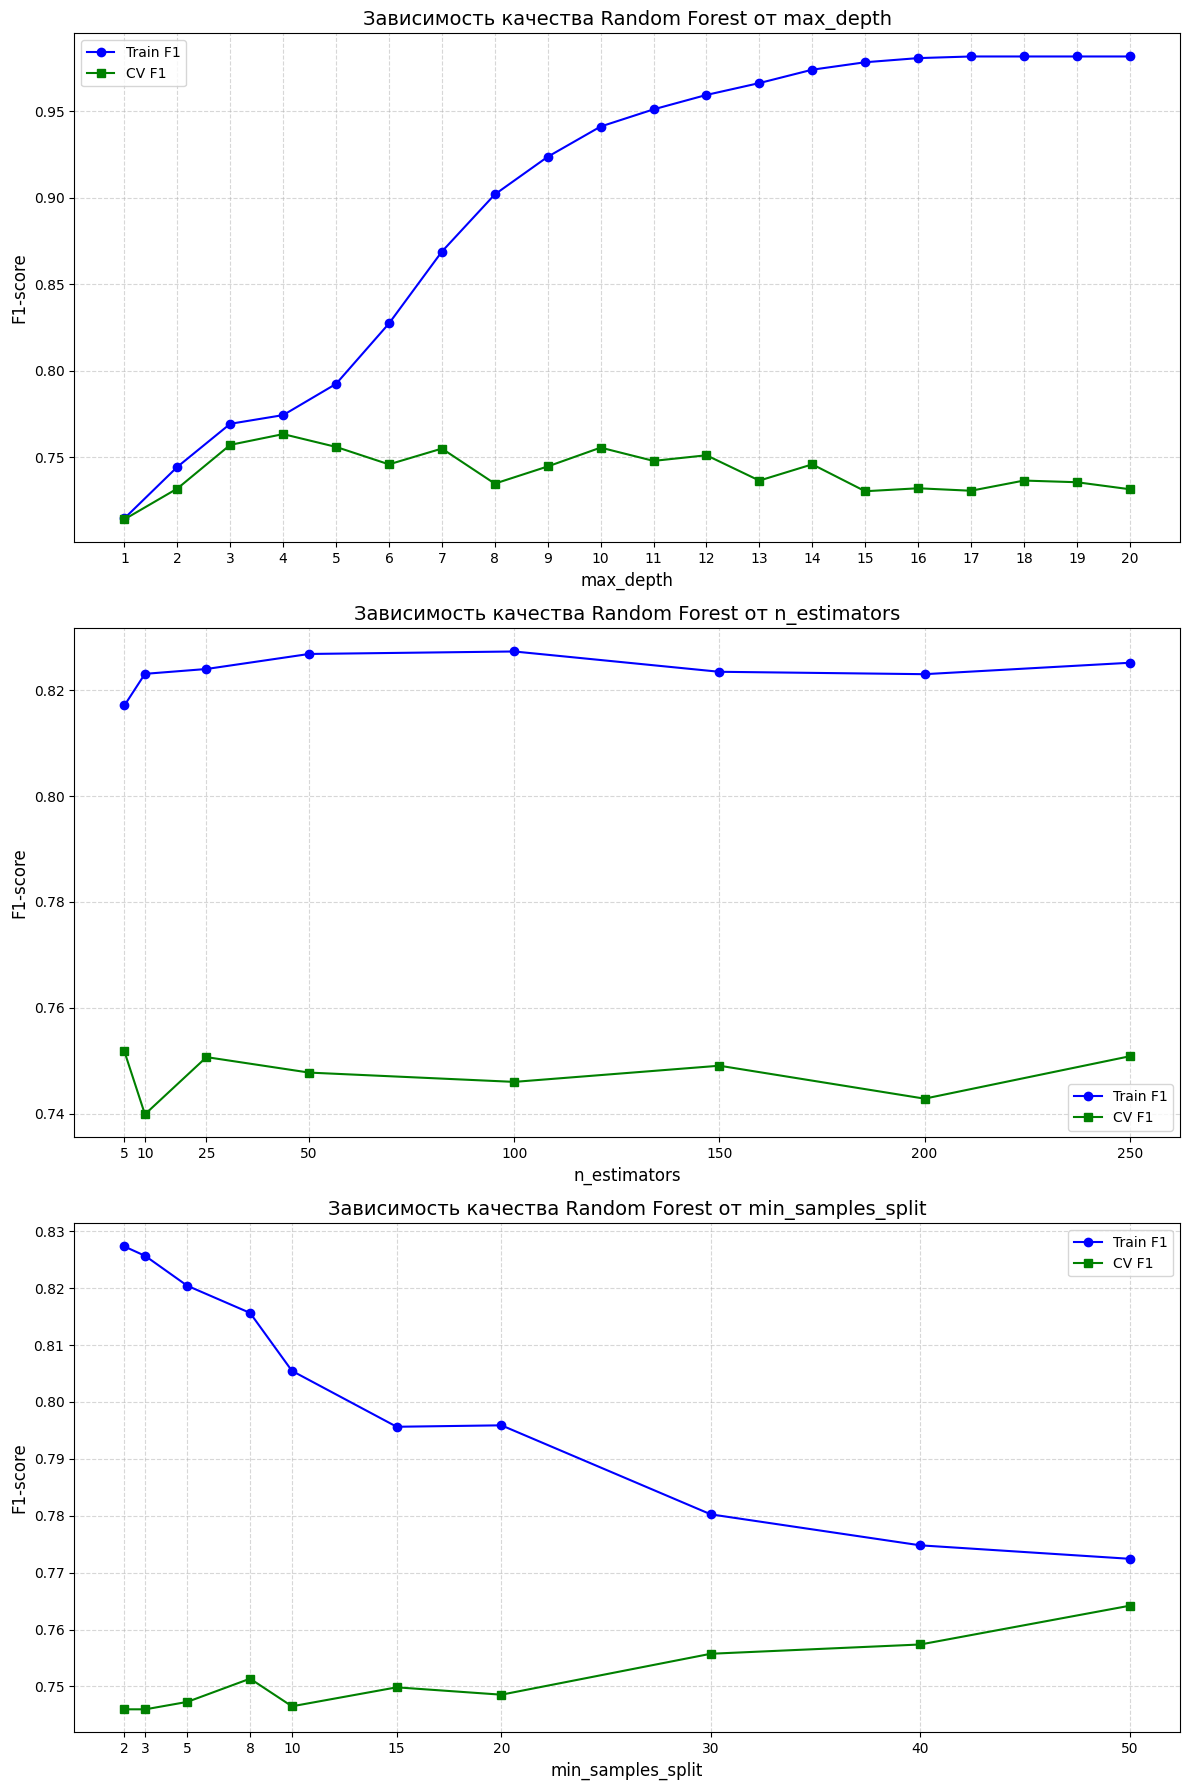

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier

# Зададим исследуемые диапазоны для всех трех параметров
param_ranges = {
    'max_depth': list(range(1, 21)),
    'n_estimators': [5, 10, 25, 50, 100, 150, 200, 250],
    'min_samples_split': [2, 3, 5, 8, 10, 15, 20, 30, 40, 50]
}

# Базовые значения (когда варьируем один параметр, остальные зафиксированы на этих значениях)
default_params = {
    'max_depth': 6,
    'n_estimators': 100,
    'min_samples_split': 2
}

fig, axes = plt.subplots(3, 1, figsize=(12, 18))

for i, (param_name, param_values) in enumerate(param_ranges.items()):
    train_scores = []
    cv_scores = []

    for val in param_values:
        # Создаем конфигурацию параметров, заменяя исследуемый параметр на текущее значение
        current_params = default_params.copy()
        current_params[param_name] = val

        model = RandomForestClassifier(**current_params, random_state=42)
        scores = cross_validate(model, X_train_t, y_train_t, cv=cv, scoring='f1', return_train_score=True)

        train_scores.append(np.mean(scores['train_score']))
        cv_scores.append(np.mean(scores['test_score']))

    # Отрисовка графиков
    ax = axes[i]
    ax.plot(param_values, train_scores, 'o-', label='Train F1', color='blue')
    ax.plot(param_values, cv_scores, 's-', label='CV F1', color='green')

    ax.set_title(f'Зависимость качества Random Forest от {param_name}', fontsize=14)
    ax.set_xlabel(param_name, fontsize=12)
    ax.set_ylabel('F1-score', fontsize=12)
    ax.set_xticks(param_values)
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()